### Criação do baseline
está sendo elimado as colunas de: 
- Churn Score - Score preditivo IBM SPSS Modeler;
- CLTV -  Calculado por fórmulas corporativas após ocorrer o churn;
- Churn Reason - Sabemos apenas após ocorrer o cancelamneto;
- Churn Label - Representação textil da categoria;
- CustomerID - Apenas um identificador do cliente;
- Count - Quantidade de registros, como um row count;
- Country - Pais do contratante, como todos são do mesmo pais é irrelevante;
- State - Estado do contratante, como todos são da California é irrelevante;
- Lat Long - Informação de latitude e longitude da cidade do contratante;

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, average_precision_score, precision_recall_curve

SEED=42

In [7]:
raw = pd.read_excel("../data/telco_customer_churn.xlsx")
df = raw.copy()

df["Total Charges"] = pd.to_numeric(
    df["Total Charges"].astype("string").str.strip().replace("", "0"),
    errors="coerce",
)

display(df.head())

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [8]:
df = df.drop(["CustomerID","Lat Long","Count","Country", "State","Churn Score","Churn Label","CLTV","Churn Reason"],axis=1)
df.columns

Index(['City', 'Zip Code', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Value'],
      dtype='str')

In [9]:
# 1. Separar Features (X) e Target (y)
X = df.drop(
    columns=[
        "Churn Value",
    ]
)
y = df["Churn Value"]

# 2. Divisão Treino e Teste ANTES de qualquer transformação (Evita Data Leakage!)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# 3. Identificar quais colunas são numéricas e quais são categóricas
# (Fazemos isso automaticamente filtrando os tipos do DataFrame)
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool", "str"]
).columns.tolist()

print(f"Variáveis Numéricas: {numeric_features}")
print(f"Variáveis Categóricas: {categorical_features}")


Variáveis Numéricas: ['Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Total Charges']
Variáveis Categóricas: ['City', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


In [19]:
# 4. Construir o Pré-processador usando ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ]
)

# 5. Criar o Pipeline completo (Pré-processamento + Modelo Baseline)
baseline_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(class_weight="balanced", random_state=42, max_iter=1000),
        ),
    ]
)

# 6. Treinar o modelo de ponta a ponta com um único comando!
baseline_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['City','Zip Code','Latitude',...,'Payment Method','Monthly Charges', 'Total Charges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='

In [20]:
# Predições
y_pred = baseline_pipeline.predict(X_test)
y_prob = baseline_pipeline.predict_proba(X_test)[:, 1]

In [22]:
# Métricas principais
print("--- Relatório de Classificação ---")
print(classification_report(y_test, y_pred))

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")

--- Relatório de Classificação ---
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.52      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409

ROC-AUC Score: 0.8364


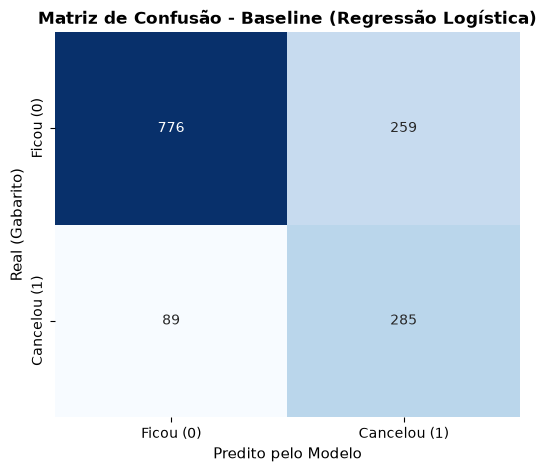

In [23]:
# Criando a Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Ficou (0)", "Cancelou (1)"],
    yticklabels=["Ficou (0)", "Cancelou (1)"],
)
plt.title(
    "Matriz de Confusão - Baseline (Regressão Logística)",
    fontsize=12,
    weight="bold",
)
plt.xlabel("Predito pelo Modelo", fontsize=11)
plt.ylabel("Real (Gabarito)", fontsize=11)
plt.show()

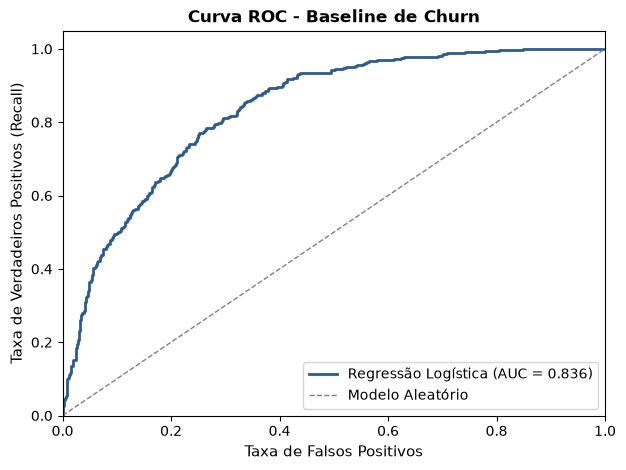

In [24]:
# Calculando a Curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_val = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr,
    tpr,
    color="#2b5c8f",
    lw=2,
    label=f"Regressão Logística (AUC = {auc_val:.3f})",
)
plt.plot(
    [0, 1], [0, 1], color="gray", linestyle="--", lw=1, label="Modelo Aleatório"
)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Taxa de Falsos Positivos", fontsize=11)
plt.ylabel("Taxa de Verdadeiros Positivos (Recall)", fontsize=11)
plt.title(
    "Curva ROC - Baseline de Churn", fontsize=12, weight="bold"
)
plt.legend(loc="lower right", frameon=True)
plt.show()

Average Precision (PR-AUC Score): 0.6247


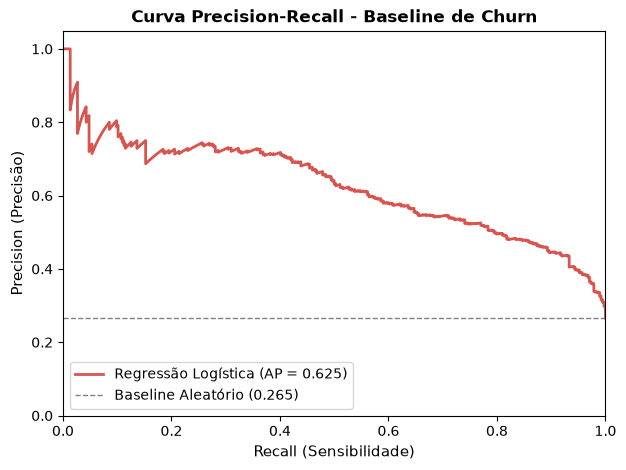

In [ ]:
# 1. Calcular o Average Precision (AP) - que resume a curva PR em um único número (equivalente ao AUC da curva PR)
ap_score = average_precision_score(y_test, y_prob)
print(f"Average Precision (PR-AUC Score): {ap_score:.4f}")

# 2. Calcular os valores da curva Precision-Recall
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

# 3. Plotar a Curva Precision-Recall
plt.figure(figsize=(7, 5))
plt.plot(
    recall,
    precision,
    color="#d9534f",
    lw=2,
    label=f"Regressão Logística (AP = {ap_score:.3f})",
)

# Linha de referência baseada na proporção de positivos na base de teste (Baseline aleatório)
proporcao_positivos = y_test.mean()
plt.axhline(
    y=proporcao_positivos,
    color="gray",
    linestyle="--",
    lw=1,
    label=f"Baseline Aleatório ({proporcao_positivos:.3f})",
)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Recall (Sensibilidade)", fontsize=11)
plt.ylabel("Precision (Precisão)", fontsize=11)
plt.title(
    "Curva Precision-Recall - Baseline de Churn", fontsize=12, weight="bold"
)
plt.legend(loc="lower left", frameon=True)
plt.show()